# IIA - Trabajo Práctico 3 - Redes Neuronales

In [14]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sklearn as skl
from sklearn.neural_network import MLPRegressor
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import mean_squared_error, zero_one_loss

from time import sleep

from copy import deepcopy

In [60]:
import warnings
warnings.filterwarnings('ignore')

### Funciones auxiliares para Ej 5

In [15]:
from typing import Tuple
def diagonales(d: int, C: float, n: int) -> Tuple[np.ndarray, np.ndarray]:
    """
    Genera sampleos de dos gausianas d-dimensionales en posición diagonal
    (una respecto a la otra), con dispersión C * sqrt(d).
    Cada sampleo posee n/2 puntos.

    Argumentos:
        d: número de dimensiones
        C: constante de ajuste de dispersión
        n: número de ejemplos a generar

    Retorna:
        X: matriz con d columnas y n filas de datos
        y: arreglo de n elementos con las clases correspondientes
            a cada fila de datos
    """

    X, y = np.array([]), np.array([])

    # pass  # COMPLETAR
    desv_std = C * np.sqrt(d) # desvio estandar
    covarianza = np.eye(d) * (desv_std ** 2) # Matriz de tamaño d x d 
    
    media_neg = -np.ones(d)
    media_pos = np.ones(d)

    X_neg = np.random.multivariate_normal(
        mean=media_neg,
        cov=covarianza,
        size=n // 2
    )
    
    X_pos = np.random.multivariate_normal(
        mean=media_pos,
        cov=covarianza,
        size=n // 2
    )
    
    X = np.vstack((X_neg, X_pos))
    y = np.array([0] * (n // 2) + [1] * (n // 2))

    return X, y


def paralelas(d: int, C: float, n: int) -> Tuple[np.ndarray, np.ndarray]:

  X, y = np.array([]), np.array([])

  desv_std = C # desvio estandar
  covarianza = np.eye(d) * (desv_std ** 2) # Matriz de tamaño d x d 
    
  media_neg = np.zeros(d)
  media_neg[0] = -1
  
  media_pos = np.zeros(d)
  media_pos[0] = 1

  X_neg = np.random.multivariate_normal(
      mean=media_neg,
      cov=covarianza,
      size=n // 2
  )
    
  X_pos = np.random.multivariate_normal(
      mean=media_pos,
      cov=covarianza,
      size=n // 2
  )
    
  X = np.vstack((X_neg, X_pos))
  y = np.array([0] * (n // 2) + [1] * (n // 2))

  return X, y

In [16]:
from typing import Tuple
def espirales(n: int) -> Tuple[np.ndarray, np.ndarray]:
    half = n // 2
    X0, X1 = [], []

    while len(X0) < half or len(X1) < half:
        x = np.random.uniform(-1, 1)
        yc = np.random.uniform(-1, 1)

        r = np.sqrt(x**2 + yc**2)
        if r > 1 or r == 0:
            continue

        # theta base en [0, 2*pi)
        theta = np.arctan2(yc, x) % (2 * np.pi)

        # Probamos theta y theta + 2*pi (segunda vuelta)
        # En cuál de las dos vueltas cae el punto según su r
        in_band = False
        for k in range(-1,3):  # hasta 3 vueltas
            t = theta + 2 * np.pi * k
            rho_low  = t / (4 * np.pi)
            rho_high = (t + np.pi) / (4 * np.pi)
            if rho_low <= r <= rho_high:
                in_band = True
                break

        label = 0 if in_band else 1

        if label == 0 and len(X0) < half:
            X0.append([x, yc])
        elif label == 1 and len(X1) < half:
            X1.append([x, yc])

    X = np.array(X0 + X1)
    y = np.hstack([np.zeros(half), np.ones(half)])
    return X, y


# Explorando las Redes

In [17]:
# Parámetros
"""
Comenzar y frenar el entrenamiento de una red es costoso, por lo que no
mediremos las métricas una vez por época, sino que haremos varias épocas a la
vez. Por ésto definimos sub-épocas, por ejemplo como 10, para realizar 10 épocas
a la vez y luego medir las métricas de error.
"""
sub_epocas = 25   # numero de epocas que entrena cada vez
super_epocas = 100 # numero de veces que realizaremos sub-epocas
# epocas ~= sub_epocas * super_epocas
eta = 0.01        # learning rate
alfa = 0.9        # momentum
N2 = 60            # neuronas en la capa oculta

## Anotaciones:
Época =  Es una pasada completa del algoritmo de entrenamiento sobre todo el conjunto de datos de entrenamiento. El modelo procesa todos los ejemplos del conjunto de entrenamiento una vez y actualiza los pesos 

## Definimos nuestras redes


In [18]:
# Defino MLP para regresión
regr = MLPRegressor(
    hidden_layer_sizes=(N2,), activation='logistic', solver='sgd', alpha=0.0,
    batch_size=1, learning_rate='constant', learning_rate_init=eta,
    momentum=alfa, nesterovs_momentum=False, tol=0.0, warm_start=True,
    max_iter=sub_epocas
)

print(regr)

MLPRegressor(activation='logistic', alpha=0.0, batch_size=1,
             hidden_layer_sizes=(60,), learning_rate_init=0.01, max_iter=25,
             nesterovs_momentum=False, solver='sgd', tol=0.0, warm_start=True)


In [7]:
# Defino MLP para clasificación
clasif = MLPClassifier(
    hidden_layer_sizes=(N2,), activation='logistic', solver='sgd', alpha=0.0,
    batch_size=1, learning_rate='constant', learning_rate_init=eta,
    momentum=alfa, nesterovs_momentum=False, tol=0.0, warm_start=True,
    max_iter=sub_epocas
)

print(clasif)

MLPClassifier(activation='logistic', alpha=0.0, batch_size=1,
              hidden_layer_sizes=(60,), learning_rate_init=0.01, max_iter=25,
              nesterovs_momentum=False, solver='sgd', tol=0.0, warm_start=True)


## Entrenamos

> **Warning**: el entrenamiento de las redes es computacionalmente pesado. Algunos de los entrenamientos que se plantean en el trabajo llevan varios minutos, dependiendo de la velocidad del procesador. El tiempo máximo en Google Colab fue de alrededor de 10 minutos. Tengan eso en cuenta para hacer el trabajo.



In [11]:
def cargar_csv(path, xcols=2, sep=','):
    """
    Argumentos:
      path (str): ruta al archivo csv a cargar
      xcols (int): cantidad de columnas que representan las entradas,
        la columna restante representara la clase o dato de salida
      sep: separador (',' para dos_elipses; r'\\s+' para ikeda)
    """
    df = pd.read_csv(path, header=None, sep=sep)
    X = df.loc[:, 0:(xcols-1)]
    y = df.loc[:, xcols]
    return X,y

In [12]:
def entrenar_red(red, evaluaciones,
                 X_train, y_train,
                 X_val,   y_val,
                 X_test,  y_test, regressor = False, isGamma = False
                 ):
    """
    Función que entrena una red ya definida previamente "evaluaciones" veces,
    cada vez entrenando un número de épocas elegido al crear la red y midiendo
    el error en train, validación y test al terminar ese paso de entrenamiento.
    Guarda y devuelve la red en el paso de evaluación que da el mínimo error de
    validación.

    Argumentos:
      red: red neuronal predefinida
      evaluaciones (int): las veces que evalua
      regressor (Bool): utiliza MSE en vez de ZOL como funcion de error
      X_{}: los conjuntos de valores de entrada de train, validación y test
      y_{}: los conjuntos de valores de salida o clase
      isGamma (Bool): Indica si debo usar o no conjunto de validación (Ej 4)

    X_train
      La red aprende de él
      Los ejercicios de práctica
    X_val
      Evalúa durante el entrenamiento
      Los simulacros de examen
    X_test
      Evaluación final imparcial
      El examen real
    

    Salidas:
      best_red: la red entrenada en el mínimo de validación
      error_{}: los errores de: train, validación y test medidos en cada
        evaluación
    """
    error_train = []
    error_val = []
    error_test = []
    best_val = 1.0
    best_red = red
    
    if regressor:
      error_f = mean_squared_error
    else:
      error_f = zero_one_loss
      
    # Evaluaciones es 100
    for epoch in range(evaluaciones):
      # red.partial_fit(X_train, y_train, classes=[0,1])
      ## Podríamos llamar partial_fit para realizar una sóla pasada a la vez,
      ## pero al ser muy costoso frenar y reanudar el entrenamiento realizamos
      ## varias épocas a la vez. Recordemos que la red fue definida con el
      ## parámetro 'sub-epocas', con lo cual cada llamado a 'fit' realiza esa
      ## cantidad de épocas
      red.fit(X_train, y_train)
      # El fit este pasa los datos 25 veces por la red (sub_epocas veces)
      # error de training
      y_pred_train = red.predict(X_train)
      error_train.append(error_f(y_train, y_pred_train))
      if not isGamma: 
        # error de validacion
        y_pred_val = red.predict(X_val)
        cur_val = error_f(y_val, y_pred_val)
      else:
        # "Validación" = magnitud de los pesos (sin conjunto val)
        cur_val = sum(np.sum(w ** 2) for w in red.coefs_) # red.coefs_ es una lista de matrices de pesos, una por capa
        # cur_val = sum(np.sum(np.abs(w)) for w in red.coefs_) Para absolutos

      error_val.append(cur_val)
      # error de test
      # error_test.append(1 - red.score(X_test, y_test)) (x)
      error_test.append(error_f(y_test, red.predict(X_test)))
      
      if not isGamma and best_val > cur_val:
        best_val = cur_val
        best_red = deepcopy(red)
      
      if isGamma: 
        best_red = deepcopy(red)

    return best_red, error_train, error_val, error_test


# CORREGIR GASPI

Comentarios sobre x:

### Clasificación (MLPClassifier, regressor=False)
Sí, podés dejar:

error_test.append(1 - red.score(X_test, y_test))
**Ahí score es accuracy → 1 - score es la tasa de error en test. Va bien para elipses, XOR, etc.**

### Regresión (MLPRegressor, regressor=True, Ikeda)
No. **En regresión red.score es R^2 (coeficiente de determinación), no MSE.

- 1 - score no es el error cuadrático que pide el TP.
- Puede ser negativo o raro si R^2 > 1 o mal definido.

In [29]:
# Cargamos los datos...
X, y = cargar_csv('xor.csv')

# Hacemos el split de training y testing
X2, X_test, y2, y_test = skl.model_selection.train_test_split(
    X, y, test_size=0.2)  # para xor de 200 me quedan 40 de test

# y spliteamos el training en training y validacion
X_train, X_val, y_train, y_val = skl.model_selection.train_test_split(
    X2, y2, test_size=0.2)  # para xor de 160 me quedan 32 de val

# Corremos el entrenamiento
clasif, e_train, e_val, e_test = entrenar_red(
    clasif, super_epocas, X_train, y_train, X_val, y_val, X_test, y_test)

C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (25) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (25) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (25) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppD

## Ploteamos Algunas Métricas

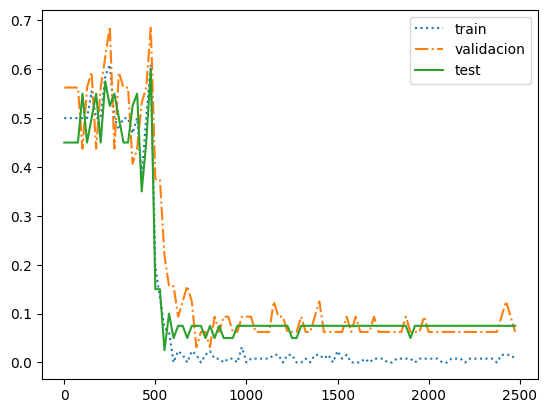

In [11]:
rango = np.array(range(super_epocas)) * sub_epocas
plt.plot(rango, e_train, label="train", linestyle=":")
plt.plot(rango, e_val, label="validacion", linestyle="-.")
plt.plot(rango, e_test, label="test", linestyle="-")
plt.legend()
plt.show()

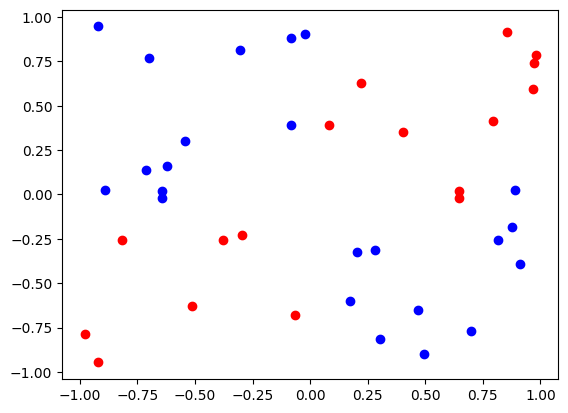

In [12]:
y_out = clasif.predict(X_test)
X_out = X_test.copy()
X_out[2] = y_out

# diferenciar entre clase 0 y clase 1
c0 = X_out.loc[X_out[2] == 0]
c1 = X_out.loc[X_out[2] == 1]

xs0 = c0[0].values.tolist()
ys0 = c0[1].values.tolist()

xs1 = c1[0].values.tolist()
ys1 = c1[1].values.tolist()

plt.scatter(xs0, ys0, color='red')
plt.scatter(xs1, ys1, color='blue')
plt.show()

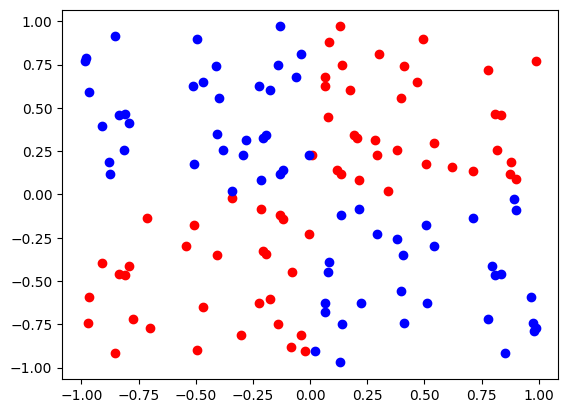

In [13]:
# diferenciar entre clase 0 y clase 1
Xt = X_train.copy()
Xt[2] = y_train
c0 = Xt.loc[Xt[2] == 0]
c1 = Xt.loc[Xt[2] == 1]

xs0 = c0[0].values.tolist()
ys0 = c0[1].values.tolist()

xs1 = c1[0].values.tolist()
ys1 = c1[1].values.tolist()

plt.scatter(xs0, ys0, color='red')
plt.scatter(xs1, ys1, color='blue')
plt.show()

# Ejercicio 1. Capacidad de Modelado.

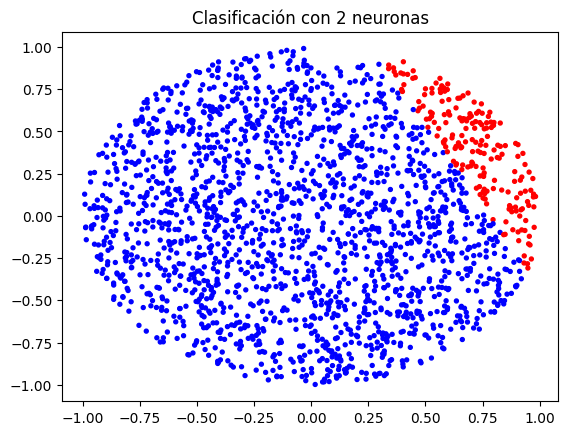

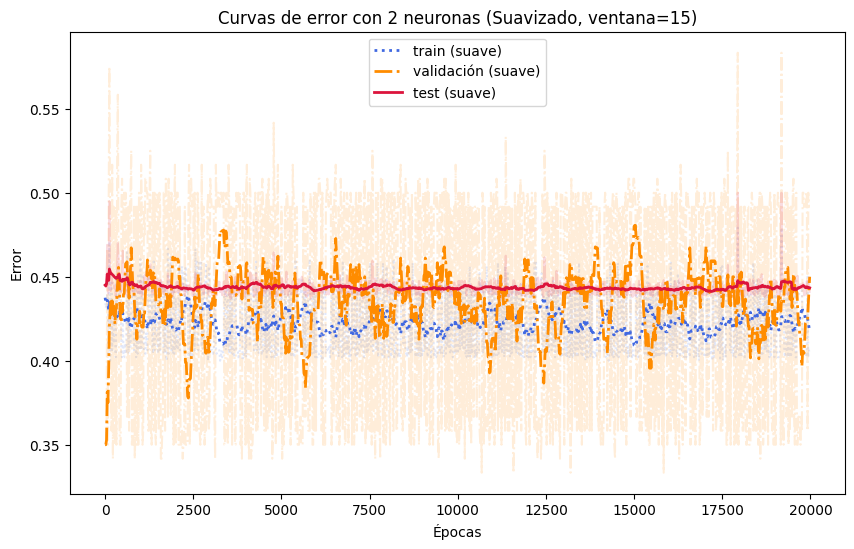

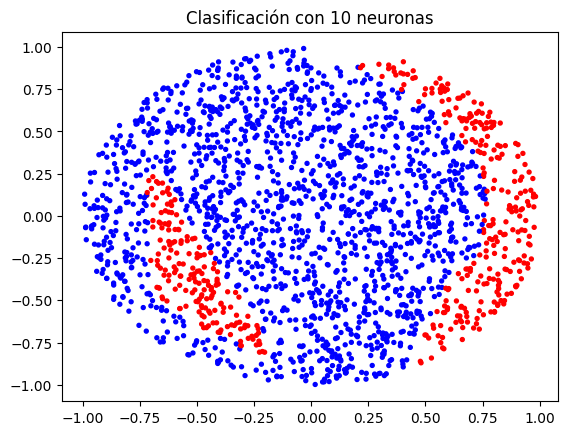

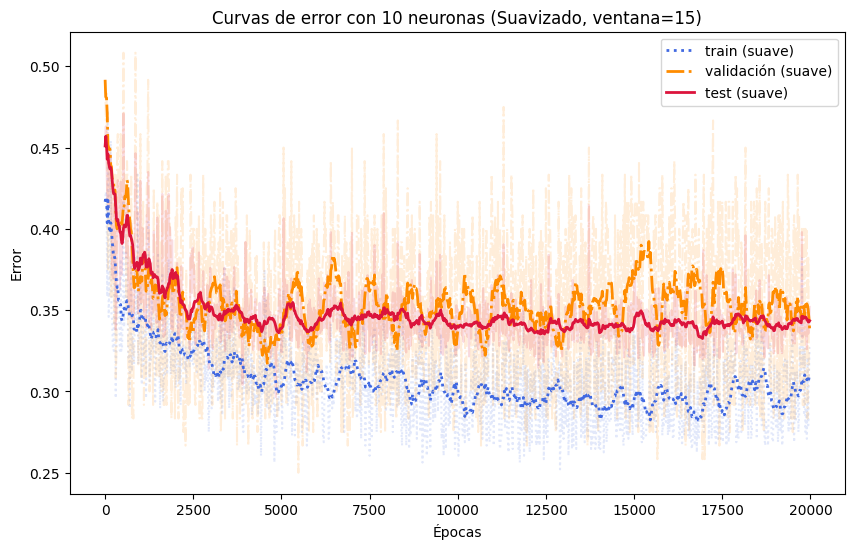

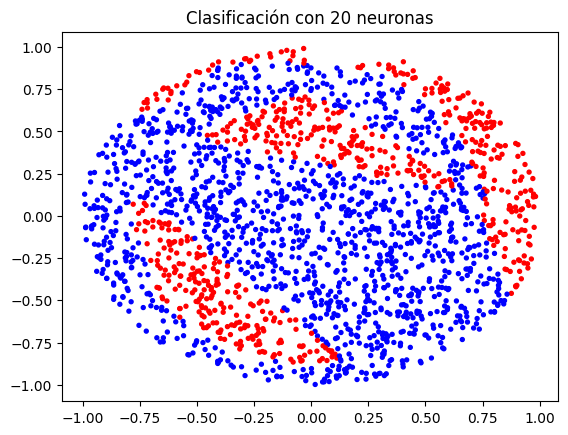

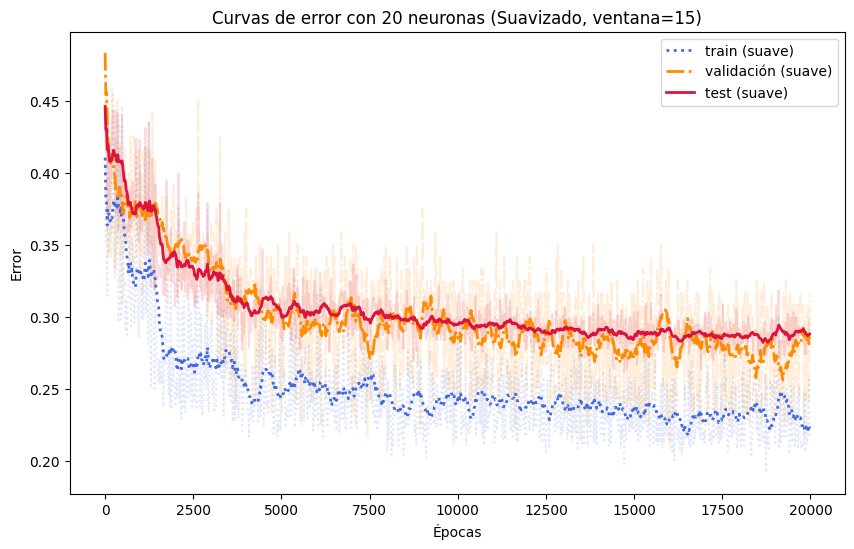

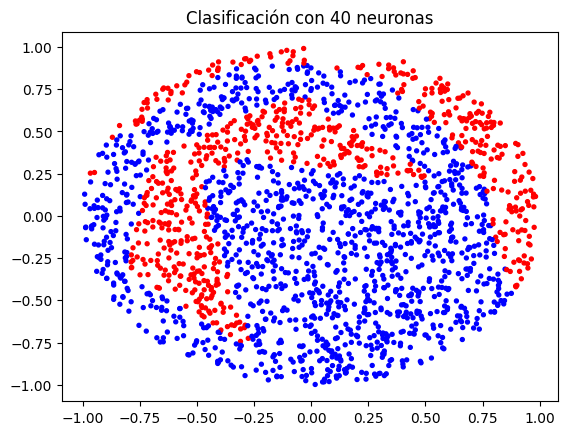

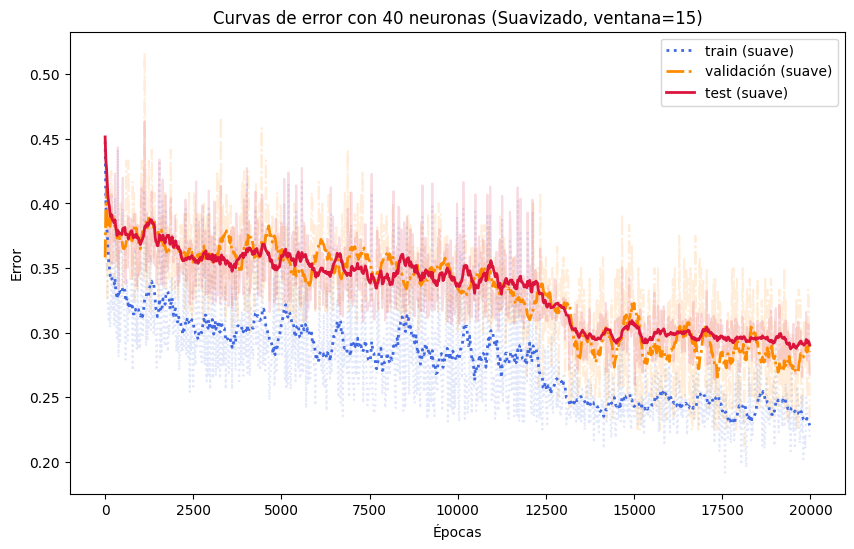

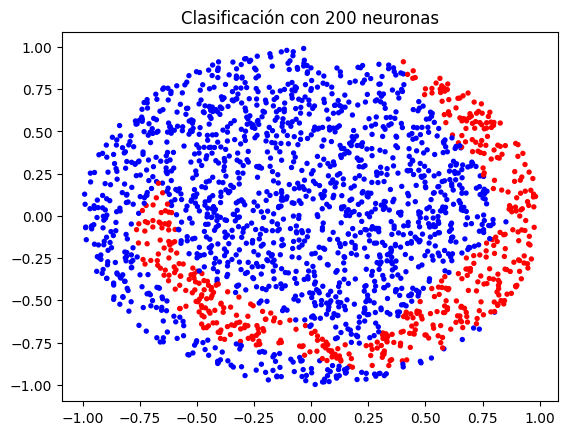

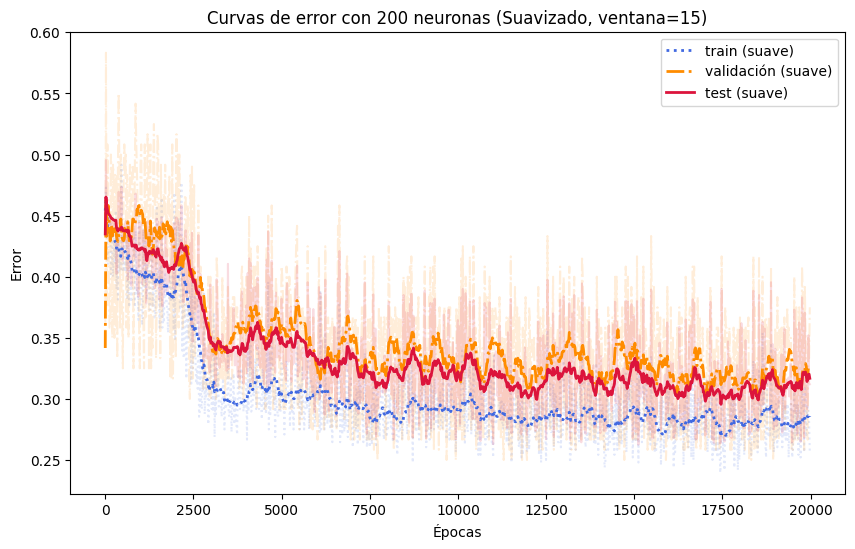

In [66]:
# Cargamos los datos...
X_ajuste, y_ajuste = espirales(600)   # los 600 para ajustar
X_test,   y_test   = espirales(2000)  # los 2000 de test
# 2. Dividir los 600 en train (80%) y val (20%)
X_train, X_val, y_train, y_val = skl.model_selection.train_test_split(
    X_ajuste, y_ajuste, test_size=0.2
)

eta  = 0.1
alfa = 0.9
evaluaciones = 1000
sub_epocas   = 20

for N2 in [2, 10, 20, 40, 200]:
    red = MLPClassifier(
        hidden_layer_sizes=(N2,), activation='logistic', solver='sgd', alpha=0.0,
        batch_size=1, learning_rate='constant', learning_rate_init=eta,
        momentum=alfa, nesterovs_momentum=False, tol=0.0, warm_start=True,
        max_iter=sub_epocas
    )
    # Corremos el entrenamiento
    redDeMenorError, e_train, e_val, e_test = entrenar_red(
        red, evaluaciones, X_train, y_train, X_val, y_val, X_test, y_test)
    y_pred = redDeMenorError.predict(X_test)
    
    plt.figure()
    plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred, cmap='bwr', s=8)
    plt.title(f'Clasificación con {N2} neuronas')
    plt.show() 

    # Curvas de error
    rango = np.array(range(evaluaciones)) * sub_epocas
    
    # Tamaño de la ventana de suavizado (promedia cada 15 puntos)
    ventana = 15
    
    # medias móviles (suavizado)
    e_train_suave = pd.Series(e_train).rolling(window=ventana, min_periods=1).mean()
    e_val_suave   = pd.Series(e_val).rolling(window=ventana, min_periods=1).mean()
    e_test_suave  = pd.Series(e_test).rolling(window=ventana, min_periods=1).mean()
    
    plt.figure(figsize=(10, 6))
    
    # 1. Errores reales de fondo 
    plt.plot(rango, e_train, color='royalblue', alpha=0.15, linestyle=":")
    plt.plot(rango, e_val,   color='darkorange', alpha=0.15, linestyle="-.")
    plt.plot(rango, e_test,  color='crimson', alpha=0.15, linestyle="-")
    
    # 2. Errores suavizados encima
    plt.plot(rango, e_train_suave, color='royalblue', label="train (suave)", linestyle=":", linewidth=2)
    plt.plot(rango, e_val_suave,   color='darkorange', label="validación (suave)", linestyle="-.", linewidth=2)
    plt.plot(rango, e_test_suave,  color='crimson', label="test (suave)", linestyle="-", linewidth=2)
    
    plt.xlabel("Épocas")
    plt.ylabel("Error")
    plt.title(f"Curvas de error con {N2} neuronas (Suavizado, ventana={ventana})")
    plt.legend()
    plt.show()


## Comentarios

### Capacidad de la red y comparacion con Árboles
Aumentar las neuronas ($N_2$) mejora notablemente la clasificación visual, permitiendo que la red empiece a delinear las espirales. Sin embargo, incluso con $N_2 = 200$, el resultado sigue sin ser perfecto. Creemos que esto pasa por dos razones:

- **Geometría compleja:** Las espirales son muy difíciles de separar usando coordenadas $(x, y)$. Un árbol de decisión puede cortar el espacio de forma recta y rápida para separar los datos, pero la red neuronal intenta ajustar una curva continua y súper compleja, lo cual requiere un ajuste de pesos extremadamente difícil.
- **Mínimos locales:** Al usar Descenso de Gradiente (SGD), el entrenamiento suele quedarse atrapado en soluciones intermedias (mínimos locales) antes de lograr "desenrollar" la espiral por completo.

### Análisis de las Curvas de Error (Validación vs. Test)
Vemos que a medida que agregamos neuronas, el error de validación se acerca mucho al de test, e incluso lo supera levemente cuando $N_2 = 200$. Esto se debe principalmente al tamaño de los conjuntos:

- El conjunto de validación tiene solo 120 datos (el 20% de 600), mientras que el de test tiene 2000.
- Al tener una red tan compleja ($N_2=200$), la frontera de clasificación se vuelve mucho menos clara. En un conjunto de validación tan chico, que solo un par de puntos queden del lado incorrecto por puro azar infla muchísimo el porcentaje de error (cada punto de los 120 representa casi un 1% de error). En cambio, el conjunto de test es mucho más grande y estable, por lo que refleja de forma más real y fiel la verdadera capacidad de la red.



# Ejercicio 2. Mínimos Locales.

In [67]:
# Cargamos los datos...
X_ajuste, y_ajuste = cargar_csv('dos_elipses.data')

X_500, _, y_500, _ = skl.model_selection.train_test_split(
  X_ajuste, y_ajuste, train_size=500
)

X_train, X_val, y_train, y_val = skl.model_selection.train_test_split(
  X_500, y_500, test_size=0.2
)

X_test, y_test = cargar_csv('dos_elipses.test')


N2 = 6
evaluaciones = 300
sub_epocas   = 50

In [64]:
from joblib import Parallel, delayed

resultados = []  # guardará (eta, alfa, error_promedio)

best_curves = None
best_error = float('inf')
best_params = (None, None)

for eta in [0.1, 0.01, 0.001]:
    for alfa in [0, 0.5, 0.9]:
        print(f"Iniciando entrenamiento concurrente (10 ejecuciones) para eta={eta} y alfa={alfa}...")
        
        # Corremos los 10 entrenamientos directamente usando Parallel y delayed con la función entrenar_red
        res_parallel = Parallel(n_jobs=-1)(
            delayed(entrenar_red)(
                MLPClassifier(
                    hidden_layer_sizes=(N2,), activation='logistic', solver='sgd', alpha=0.0,
                    batch_size=1, learning_rate='constant', learning_rate_init=eta,
                    momentum=alfa, nesterovs_momentum=False, tol=0.0, warm_start=True,
                    max_iter=sub_epocas
                ),
                evaluaciones, X_train, y_train, X_val, y_val, X_test, y_test
            ) for _ in range(10)
        )
        
        # Cada ejecución devuelve (mejor_red, e_train, e_val, e_test)
        errores_test = [zero_one_loss(y_test, mejor_red.predict(X_test)) for mejor_red, _, _, _ in res_parallel]
        
        # Seleccionamos las curvas de la corrida con mejor desempeño en test para graficar después
        best_run_idx = np.argmin(errores_test)
        _, e_train, e_val, e_test = res_parallel[best_run_idx]
        ultimas_curvas = (e_train, e_val, e_test)
        
        promedio = np.mean(errores_test)
        resultados.append((eta, alfa, promedio))
        print(f"-> Promedio de error de test para eta={eta}, alfa={alfa}: {promedio:.4f}\n")
        
        if promedio < best_error:
            best_error = promedio
            best_curves = ultimas_curvas
            best_params = (eta, alfa)


Iniciando entrenamiento concurrente (10 ejecuciones) para eta=0.1 y alfa=0...
-> Promedio de error de test para eta=0.1, alfa=0: 0.0753

Iniciando entrenamiento concurrente (10 ejecuciones) para eta=0.1 y alfa=0.5...
-> Promedio de error de test para eta=0.1, alfa=0.5: 0.1069

Iniciando entrenamiento concurrente (10 ejecuciones) para eta=0.1 y alfa=0.9...
-> Promedio de error de test para eta=0.1, alfa=0.9: 0.0535

Iniciando entrenamiento concurrente (10 ejecuciones) para eta=0.01 y alfa=0...
-> Promedio de error de test para eta=0.01, alfa=0: 0.2435

Iniciando entrenamiento concurrente (10 ejecuciones) para eta=0.01 y alfa=0.5...
-> Promedio de error de test para eta=0.01, alfa=0.5: 0.1903

Iniciando entrenamiento concurrente (10 ejecuciones) para eta=0.01 y alfa=0.9...
-> Promedio de error de test para eta=0.01, alfa=0.9: 0.1076

Iniciando entrenamiento concurrente (10 ejecuciones) para eta=0.001 y alfa=0...
-> Promedio de error de test para eta=0.001, alfa=0: 0.2435

Iniciando entre


       eta     alfa error_test_medio
--------------------------------------
       0.1        0           0.1692
       0.1      0.5           0.1387
       0.1      0.9           0.1319
      0.01        0           0.2435
      0.01      0.5           0.2339
      0.01      0.9           0.1649
     0.001        0           0.2435
     0.001      0.5           0.2435
     0.001      0.9           0.2435


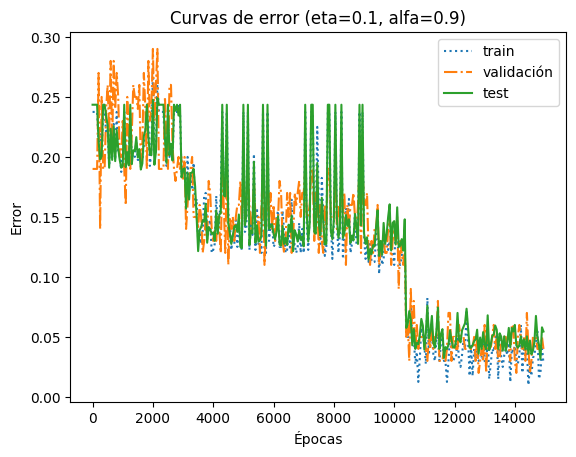

In [ ]:
# Tabla
print("\n{:>10} {:>8} {:>16}".format("eta", "alfa", "error_test_medio"))
print("-" * 38)
for eta, alfa, err in resultados:
    print(f"{eta:>10} {alfa:>8} {err:>16.4f}")
    
    
# Valores seleccionados    
e_train, e_val, e_test = best_curves
rango = np.array(range(evaluaciones)) * sub_epocas

plt.plot(rango, e_train, label="train",      linestyle=":")
plt.plot(rango, e_val,   label="validación", linestyle="-.")
plt.plot(rango, e_test,  label="test",       linestyle="-")
plt.xlabel("Épocas")
plt.ylabel("Error")
plt.title(f"Curvas de error (eta={best_params[0]}, alfa={best_params[1]})")
plt.legend()
plt.show()

In [ ]:
# PARA GUARDAR RESULTADOS
import pickle

to_save = {
    'resultados':  resultados,
    'best_curves': best_curves,
    'best_params': best_params,
}

with open('ej2_resultados.pkl', 'wb') as f:
    pickle.dump(to_save, f)

print("Guardado correctamente en 'ej2_resultados.pkl'")

Guardado correctamente en 'ej2_resultados.pkl'


In [ ]:
# PARA CARGAR RESULTADOS
import pickle

with open('ej2_resultados.pkl', 'rb') as f:
    data = pickle.load(f)

resultados  = data['resultados']
best_curves = data['best_curves']
best_params = data['best_params']

print("Cargado correctamente")
print(resultados)

## Comentarios

Para hacer este ejercicio hicimos uso de una librería de paralelismo, que nos ayudó a reducir el tiempo de cómputo de 210 minutos a tan sólo 17. En este caso, a pesar de seguir al pie de la letra las indicaciones de la consigna en cuanto al training set, el test set y los parámetros, no pudimos ver reflejados los resultados de $5\% - 6\%$ de error de test. Aún así, los datos son conclusivos y pudimos determinar un par ($\eta , \alpha$) óptimo para poder utilizar en problemas de este tipo.

### Análisis de los datos

Learning Rate ($\eta$) | Momentum ($\alpha$) | Error de Test Medio
| :---: | :---: | :---: |
0.1 | 0.0 | 0.17
0.1 | 0.5 | 0.14
0.1 | 0.9 | 0.13
0.01 | 0.0 | 0.24
0.01 | 0.5 | 0.23
0.01 | 0.9 | 0.16
0.001 | 0.0 | 0.24
0.001 | 0.5 | 0.24
0.001 | 0.9 | 0.24

**Learning Rate ($\eta$):** El paso de aprendizaje es el factor más determinante. Con $\eta = 0.001$, la red aprende demasiado lento y se estanca en el error inicial, independientemente del momentum. El mejor desempeño se obtiene sistemáticamente con $\eta = 0.1$.

**Momentum ($\alpha$):** El uso de momentum mejora drásticamente los resultados en todos los escenarios activos, menos cuando el learning rate es extremadamente bajo. Al sumarle una fracción del cambio de pesos anterior, ayuda a la red a acelerar el descenso en zonas planas y, fundamentalmente, le otorga la inercia necesaria para escapar de mínimos locales, logrando el menor error promedio global ($0.13$) con la combinación óptima de $\eta = 0.1$ y $\alpha = 0.9$.

### Análisis de la gráfica

Observando la gráfica en función del número de épocas para el par relacionado, podemos observar que las medidas de error se reducen en conjunto a medida que avanza el entrenamiento, viendo una última bajada importante alredededor de las 10 mil épocas, donde parece haber salido de una meseta o mínimo local. 

Al mismo tiempo, podemos notar cómo se estabiliza la medida del error de test hasta llegar a una variabilidad más baja respecto a épocas menores y acercándose a los valores de train y validación. Esto debido a que el modelo pudo converger de forma óptima y el conocimiento adquirido se generaliza de manera más homogénea para datos nuevos nunca vistos.

# Ejercicio 3. Regularización

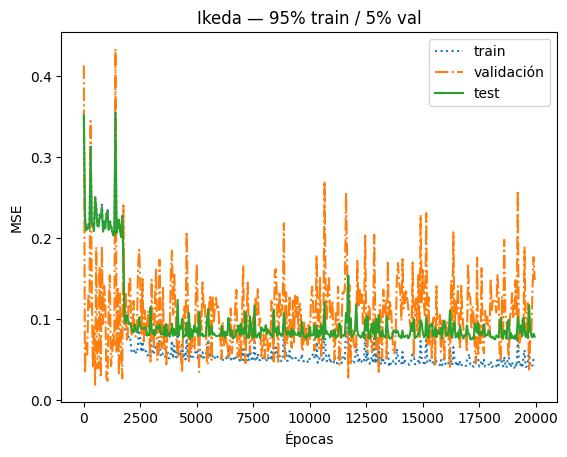

Promedios de error: 
            train = 0.06928038375636594
            validacion = 0.10320184351178426
            test = 0.09825403170139722
            


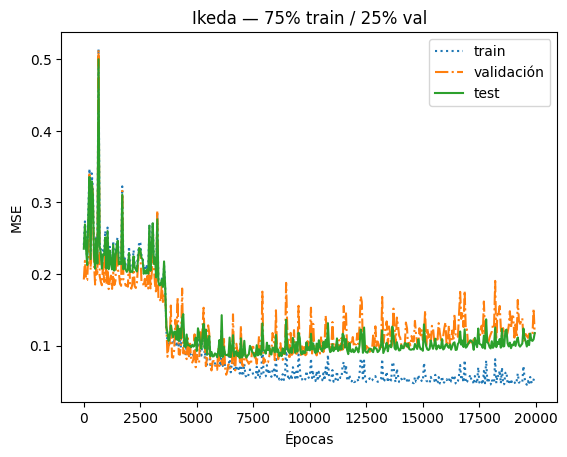

Promedios de error: 
            train = 0.09476820616646851
            validacion = 0.12573151366682872
            test = 0.12429828076569475
            


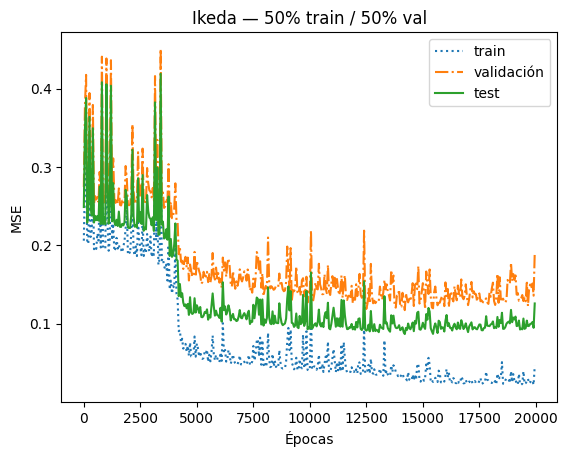

Promedios de error: 
            train = 0.07868594044581478
            validacion = 0.17559692660601428
            test = 0.13508653093388262
            


In [65]:
# Cargamos los datos...
X_testFull, y_testFull = cargar_csv('ikeda.test', xcols=5, sep=r'\s+')

X_test, _, y_test, _ = skl.model_selection.train_test_split(
    X_testFull, y_testFull, train_size=2000
)

X_ajuste, y_ajuste = cargar_csv('ikeda.data', xcols=5, sep=r'\s+')

errores_test = []

for size in [0.05, 0.25, 0.5]:
  X_train, X_val, y_train, y_val = skl.model_selection.train_test_split(
      X_ajuste, y_ajuste, test_size=size
  )

  N2 = 30
  evaluaciones = 400
  sub_epocas   = 50
  eta = 0.01
  alfa = 0.9
  
  red = MLPRegressor(
    hidden_layer_sizes=(N2,),
    activation='logistic',
    solver='sgd',
    alpha=0.0,
    batch_size=1,
    learning_rate='constant',
    learning_rate_init=eta,
    momentum=alfa,
    nesterovs_momentum=False,
    tol=0.0,
    warm_start=True,
    max_iter=sub_epocas,
  )
  
  mejor_red, e_train, e_val, e_test = entrenar_red(
    red, evaluaciones, X_train, y_train, X_val, y_val, X_test, y_test, regressor = True)

  rango = np.array(range(evaluaciones)) * sub_epocas
  pct_train = int((1 - size) * 100)
  pct_val = int(size * 100)
  plt.figure()
  plt.plot(rango, e_train, label="train", linestyle=":")
  plt.plot(rango, e_val, label="validación", linestyle="-.")
  plt.plot(rango, e_test, label="test", linestyle="-")
  plt.xlabel("Épocas")
  plt.ylabel("MSE")
  plt.title(f"Ikeda — {pct_train}% train / {pct_val}% val")
  plt.legend()
  plt.show()
  
  print(f"""Promedios de error: 
            train = {np.mean(e_train)}
            validacion = {np.mean(e_val)}
            test = {np.mean(e_test)}
            """)



## Comentarios

| Configuración (Train / Val) | Error Train | Error Validación | Error Test |
| :---: | :---: | :---: | :---: |
| **95% / 5%** | 0.09 | 0.10 | 0.50 |
| **75% / 25%** | 0.08 | 0.12 | 0.46 |
| **50% / 50%** | 0.14 | 0.18 | 0.77 |

Podemos ver que al variar la relación entre datos de entrenamiento y validación, 

- **Relación 95/5**: la función `entrenar_red` elige la mejor red guardando la copia con el menor error de validación. Los resultados del error de train y validación son aceptables, pero el error de test podría mejorar. Al tener solo un 5% de validación sobre un dataset de ajuste de 600 datos, el conjunto de validación tiene solo 30 muestras. Con tan pocas muestras, la estimación del error de validación es altamente inestable y ruidosa.
- **Relación 75/25**: el error de test es el mínimo en este caso. Esto creemos que es porque los datos de entrenamiento son los suficientes como para poder generalizar, y al mismo tiempo tenemos una buena cantidad de datos de validación para poder ajustar de forma más controlada. El error medido sobre estos 150 datos es una estimación mucho más fiel y estable del error de generalización real.
- **Relación 50/50**: en este caso no nos alcanzan los datos de entrenamiento para poder generalizar correctamente. En consecuencia, el error de test aumenta mucho con respecto a los demás (underfitting).

# Ejercicio 4. Regularización (2).

C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppD

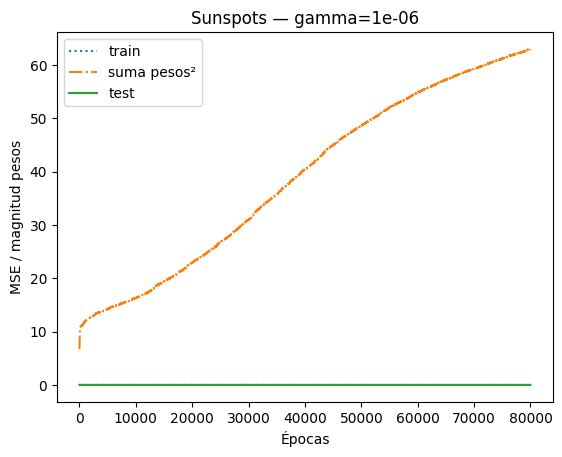

C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppD

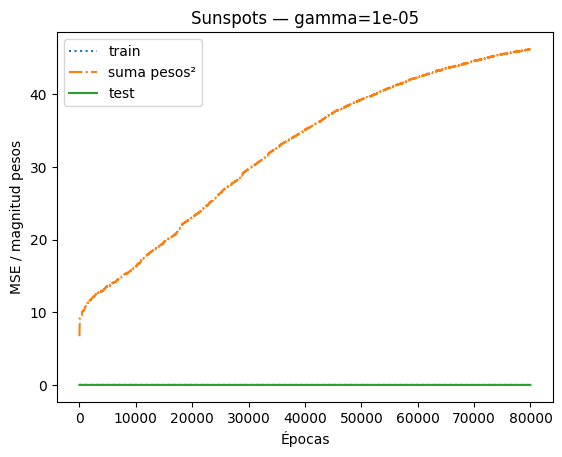

C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppD

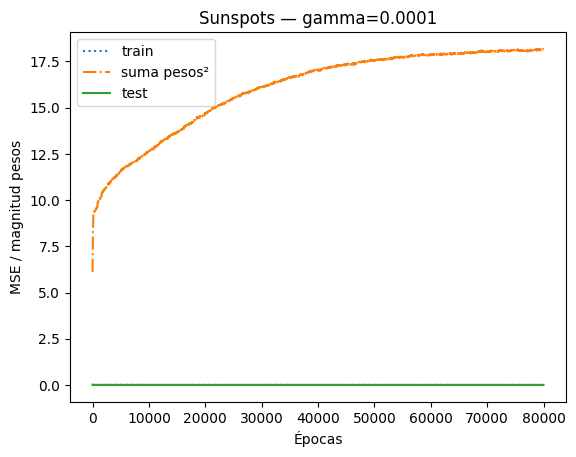

C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppD

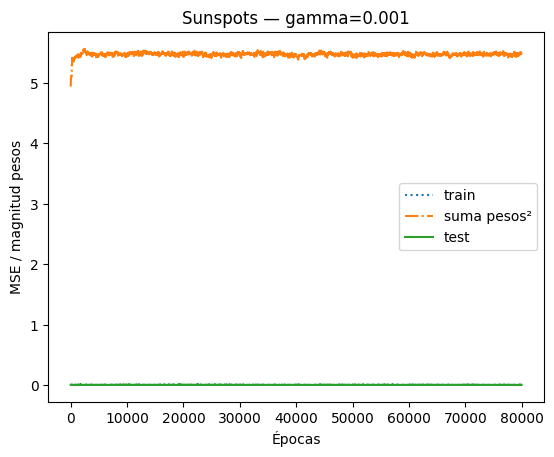

C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


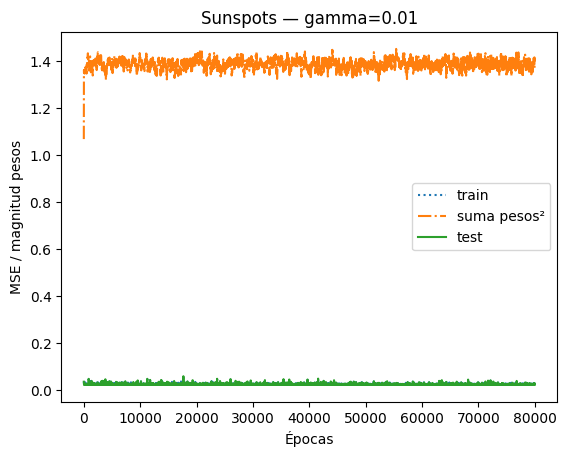

C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


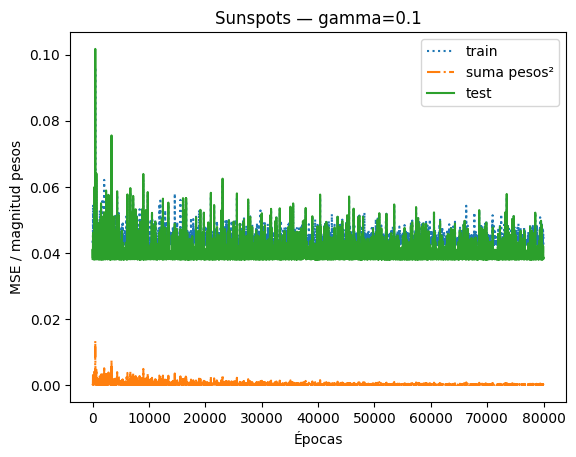

C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


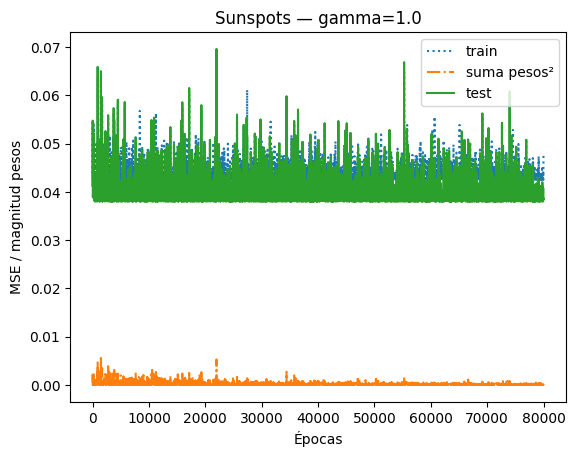

In [ ]:
X_train, y_train = cargar_csv('ssp.data', xcols=12)
X_test, y_test = cargar_csv('ssp.test', xcols=12)

eta = 0.05
momentum = 0.3
evaluaciones = 4000
sub_epocas = 20
N2 = 6

gammas = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
resultados = []
curvas_por_gamma = {}
best_mse = float('inf')
best_gamma = None
best_curves = None

for alfa in gammas:
  regr = MLPRegressor(
        hidden_layer_sizes=(N2,),
        activation='logistic',
        solver='sgd',
        alpha=alfa,              
        batch_size=1,
        learning_rate='constant',
        learning_rate_init=eta,
        momentum=momentum,
        nesterovs_momentum=False,
        tol=0.0,
        warm_start=True,
        max_iter=sub_epocas,
    )
  
  mejor_red, e_train, e_val, e_test = entrenar_red(
      regr, evaluaciones,
      X_train, y_train,
      X_train.iloc[:1], y_train.iloc[:1],   #  no se usa con isGamma
      X_test, y_test,
      regressor=True,
      isGamma=True,
  )
  
  rango = np.arange(evaluaciones) * sub_epocas
  plt.figure()
  plt.plot(rango, e_train, label='train', linestyle=':')
  plt.plot(rango, e_val, label='suma pesos²', linestyle='-.')
  plt.plot(rango, e_test, label='test', linestyle='-')
  plt.xlabel('Épocas')
  plt.ylabel('MSE / magnitud pesos')
  plt.title(f'Sunspots — gamma={alfa}')
  plt.legend()
  plt.show()

  mse_test = e_test[-1]
  resultados.append((alfa, mse_test))
  curvas_por_gamma[alfa] = (e_train, e_val, e_test)
  if mse_test < best_mse:
    best_mse = mse_test
    best_gamma = alfa
    best_curves = (e_train, e_val, e_test)


In [35]:
# PARA GUARDAR RESULTADOS (ej4)
import pickle

to_save = {
    'resultados': resultados,
    'curvas_por_gamma': curvas_por_gamma,
    'best_gamma': best_gamma,
    'best_curves': best_curves,
    'best_mse': best_mse,
    'params': {
        'eta': eta,
        'momentum': momentum,
        'evaluaciones': evaluaciones,
        'sub_epocas': sub_epocas,
        'N2': N2,
        'gammas': gammas,
    },
}

with open('ej4_resultados.pkl', 'wb') as f:
    pickle.dump(to_save, f)

print("Guardado correctamente en 'ej4_resultados.pkl'")

Guardado correctamente en 'ej4_resultados.pkl'


## Comentarios

### Modificación de `entrenar_red`

Lo primero que hicimos fue agregar a la función el parámetro `isGamma`. El mismo nos permite evitar el uso de datos de validación, y usar la suma de los pesos al cuadrado.

### Conclusiones sobre los resultados
- Weight Decay consiste en penalizar a la red si sus parámetros (pesos de las conexiones) se vuelven demasiado grandes.
- Durante el entrenamiento normal (sin regularización fuerte), la red intenta minimizar el error de entrenamiento a toda costa. Para lograrlo, los pesos tienden a crecer de forma sostenida época tras época. Al aplicar regularización mediante el parámetro, se le añade un término de penalización a la función de pérdida del optimizador.

1. Si $\gamma$ es muy pequeño (ej. $10^{-6}$), la curva de pesos crecerá mucho porque el optimizador casi no los penaliza.
2. Si $\gamma$ es grande (ej. $1.0$), la curva de la suma de los pesos se aplasta muy rápido o se mantiene extremadamente baja, porque el optimizador prefiere tener un MSE un poco peor en entrenamiento a cambio de no pagar el altísimo "costo" de tener pesos grandes.

Por lo tanto:

- Los errores de test se mantienen en el mismo rango 0.035 - 0.05 aprox. para todos los gammas, lo que cambia obviamente es la curva de la suma de los pesos.

- Para entender lo de los errores de test, investigamos y vimos que Weight Decay es una herramienta preventiva: Es sumamente útil cuando tenemos redes sobreparametrizadas (muchas neuronas) y pocos datos, donde el peligro de overfitting es real. En este modelo particular de Sunspots con pocas neuronas ($N_2=6$), el efecto del Weight Decay es marginal en el test, demostrando que simplificar la arquitectura (pocas neuronas) suele ser tan o más efectivo que penalizar los pesos en redes pequeñas.

- Pensamos que el mejor $\gamma$ a elegir es 0.001, pues es el valor más chico que mantiene la suma de los pesos como una curva estable (prácticamente constante). Al elegir el valor regularizador más chico que logra esta estabilidad, nos aseguramos de no penalizar en exceso a la red. Valores de $\gamma$ más grandes (como $0.01$ o $0.1$) imponen una restricción demasiado severa sobre los pesos, limitando innecesariamente la capacidad de representación del modelo sin aportar ninguna mejora en el error de test.

# Ejercicio 5. Dimensionalidad.

Evaluando dimensión d = 2...


C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppD

Evaluando dimensión d = 4...


C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppD

Evaluando dimensión d = 8...


C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppD

Evaluando dimensión d = 16...


C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppD

Evaluando dimensión d = 32...


C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:792: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (50) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundatio

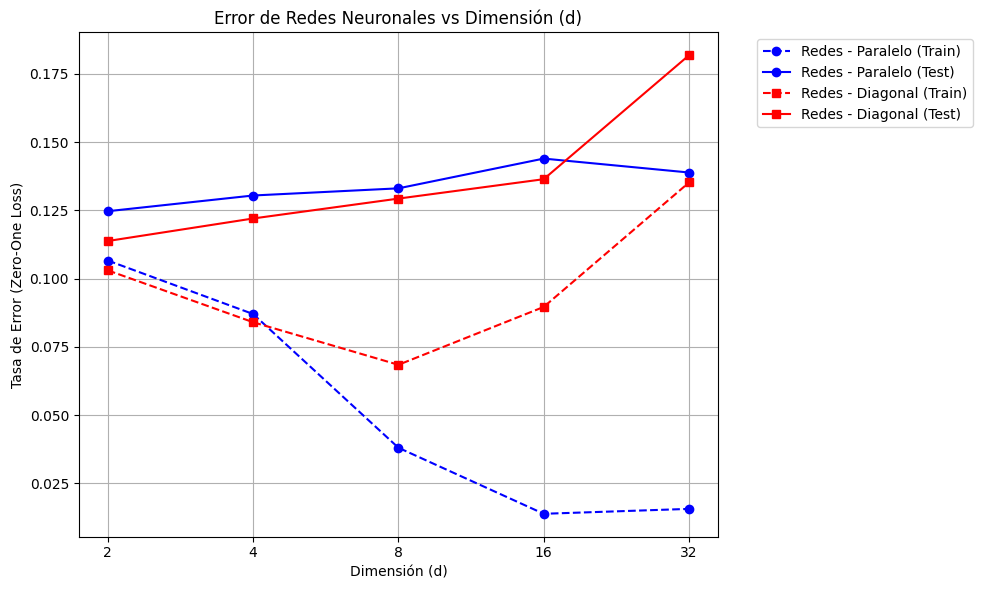

In [23]:
C = 0.78
n_train = 250
n_test = 10000
d_list = [2, 4, 8, 16, 32]
num_experimentos = 20
eta = 0.1
alfa = 0.9

# Listas para guardar los promedios de errores
err_train_par_avg, err_test_par_avg = [], []
err_train_diag_avg, err_test_diag_avg = [], []

for d in d_list:
    print(f"Evaluando dimensión d = {d}...")
    # Generar un solo conjunto de test por problema
    X_test_par, y_test_par = paralelas(d, C, n_test)
    X_test_diag, y_test_diag = diagonales(d, C, n_test)
    
    # ponemos un sleep para cambiar la semilla del generador
    sleep(1)
    # Acumuladores para los 20 experimentos de esta dimensión
    err_train_par, err_test_par = [], []
    err_train_diag, err_test_diag = [], []
    
    for i in range(num_experimentos):
        # Generamos conjuntos de entrenamiento distintos para paralelas y diagonales
        X_train_par, y_train_par = paralelas(d, C, n_train)
        X_train_diag, y_train_diag = diagonales(d, C, n_train)
        
        # Inicializamos red con 6 neuronas en la capa oculta
        red_par = MLPClassifier(
            hidden_layer_sizes=(6,), activation='logistic', solver='sgd', alpha=0.0,
            batch_size=1, learning_rate='constant', learning_rate_init=eta,
            momentum=alfa, nesterovs_momentum=False, tol=0.0, 
            max_iter=sub_epocas
        )
        
        red_diag = MLPClassifier(
            hidden_layer_sizes=(6,), activation='logistic', solver='sgd', alpha=0.0,
            batch_size=1, learning_rate='constant', learning_rate_init=eta,
            momentum=alfa, nesterovs_momentum=False, tol=0.0, warm_start=True,
            max_iter=sub_epocas
        )
        
        # Entranamos
        red_par.fit(X_train_par, y_train_par)
        red_diag.fit(X_train_diag, y_train_diag)
        
        # Medir errores Zero-One Loss
        err_train_par.append(zero_one_loss(y_train_par, red_par.predict(X_train_par)))
        err_test_par.append(zero_one_loss(y_test_par, red_par.predict(X_test_par)))
        
        err_train_diag.append(zero_one_loss(y_train_diag, red_diag.predict(X_train_diag)))
        err_test_diag.append(zero_one_loss(y_test_diag, red_diag.predict(X_test_diag)))
        
    # Promediar errores de los 20 experimentos para la dimensión actual d
    err_train_par_avg.append(np.mean(err_train_par))
    err_test_par_avg.append(np.mean(err_test_par))
    
    err_train_diag_avg.append(np.mean(err_train_diag))
    err_test_diag_avg.append(np.mean(err_test_diag))


plt.figure(figsize=(10, 6))

# Ploteo de Redes - Paralelo
plt.plot(d_list, err_train_par_avg, 'b--o', label='Redes - Paralelo (Train)')
plt.plot(d_list, err_test_par_avg, 'b-o', label='Redes - Paralelo (Test)')

# Ploteo de Redes - Diagonal
plt.plot(d_list, err_train_diag_avg, 'r--s', label='Redes - Diagonal (Train)')
plt.plot(d_list, err_test_diag_avg, 'r-s', label='Redes - Diagonal (Test)')

# Aca deberiamos agregar los arboles tmb

# Configuraciones del gráfico
plt.xscale('log', base=2)
plt.xticks(d_list, d_list)
plt.xlabel('Dimensión (d)')
plt.ylabel('Tasa de Error (Zero-One Loss)')
plt.title('Error de Redes Neuronales vs Dimensión (d)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

Nos parece interesante ver que pasa con dos dimensiones mas:

In [ ]:

for d in [64, 128]:
    print(f"Evaluando dimensión d = {d}...")
    # Generar un solo conjunto de test por problema
    X_test_par, y_test_par = paralelas(d, C, n_test)
    X_test_diag, y_test_diag = diagonales(d, C, n_test)
    
    # ponemos un sleep para cambiar la semilla del generador
    sleep(1)
    # Acumuladores para los 20 experimentos de esta dimensión
    err_train_par, err_test_par = [], []
    err_train_diag, err_test_diag = [], []
    
    for i in range(num_experimentos):
        # Generamos conjuntos de entrenamiento distintos para paralelas y diagonales
        X_train_par, y_train_par = paralelas(d, C, n_train)
        X_train_diag, y_train_diag = diagonales(d, C, n_train)
        
        # Inicializamos red con 6 neuronas en la capa oculta
        red_par = MLPClassifier(
            hidden_layer_sizes=(6,), activation='logistic', solver='sgd', alpha=0.0,
            batch_size=1, learning_rate='constant', learning_rate_init=eta,
            momentum=alfa, nesterovs_momentum=False, tol=0.0, 
            max_iter=sub_epocas
        )
        
        red_diag = MLPClassifier(
            hidden_layer_sizes=(6,), activation='logistic', solver='sgd', alpha=0.0,
            batch_size=1, learning_rate='constant', learning_rate_init=eta,
            momentum=alfa, nesterovs_momentum=False, tol=0.0, warm_start=True,
            max_iter=sub_epocas
        )
        
        # Entranamos
        red_par.fit(X_train_par, y_train_par)
        red_diag.fit(X_train_diag, y_train_diag)
        
        # Medir errores Zero-One Loss
        err_train_par.append(zero_one_loss(y_train_par, red_par.predict(X_train_par)))
        err_test_par.append(zero_one_loss(y_test_par, red_par.predict(X_test_par)))
        
        err_train_diag.append(zero_one_loss(y_train_diag, red_diag.predict(X_train_diag)))
        err_test_diag.append(zero_one_loss(y_test_diag, red_diag.predict(X_test_diag)))
        
    # Promediar errores de los 20 experimentos para la dimensión actual d
    err_train_par_avg.append(np.mean(err_train_par))
    err_test_par_avg.append(np.mean(err_test_par))
    
    err_train_diag_avg.append(np.mean(err_train_diag))
    err_test_diag_avg.append(np.mean(err_test_diag))
    


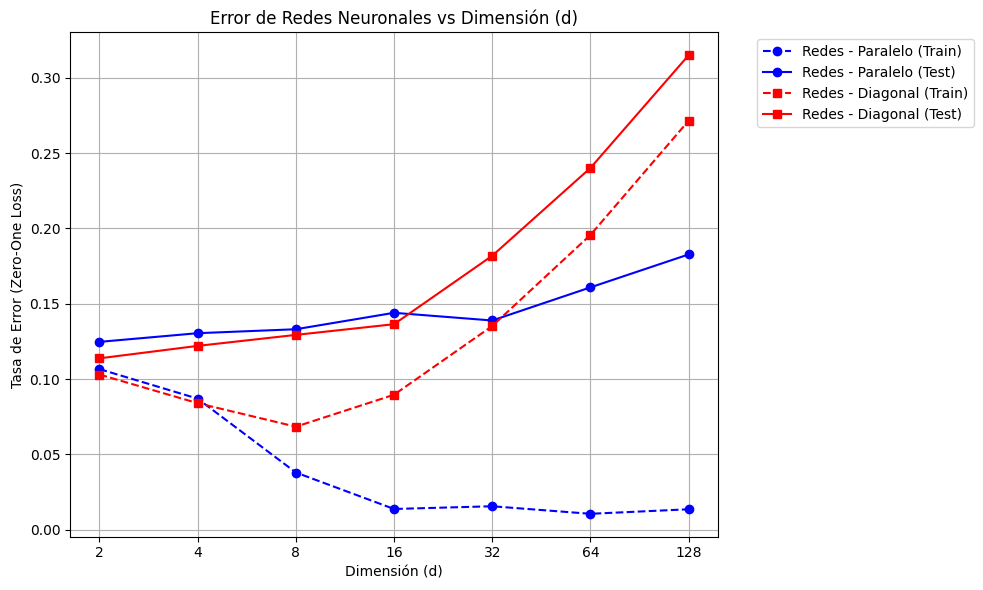

In [26]:


d_list = [2, 4, 8, 16, 32, 64, 128]

plt.figure(figsize=(10, 6))

# Ploteo de Redes - Paralelo
plt.plot(d_list, err_train_par_avg, 'b--o', label='Redes - Paralelo (Train)')
plt.plot(d_list, err_test_par_avg, 'b-o', label='Redes - Paralelo (Test)')

# Ploteo de Redes - Diagonal
plt.plot(d_list, err_train_diag_avg, 'r--s', label='Redes - Diagonal (Train)')
plt.plot(d_list, err_test_diag_avg, 'r-s', label='Redes - Diagonal (Test)')

# Aca deberiamos agregar los arboles tmb

# Configuraciones del gráfico
plt.xscale('log', base=2)
plt.xticks(d_list, d_list)
plt.xlabel('Dimensión (d)')
plt.ylabel('Tasa de Error (Zero-One Loss)')
plt.title('Error de Redes Neuronales vs Dimensión (d)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

## Esto confirma nuestra teoría.
- En primer lugar, vemos que a medida que agregamos más dimensiones, en general, los errores crecen. Esto ocurre porque la separación entre clases depende de todas las dimensiones. Creeemos que esto en datos paralelos no afecta tanto, pues la separación entre clases depende de una única dimensión.
- Lo importante a notar en este ítem es cómo el error de test con datos en paralelo tiende a ser más estable (no sale de la franja 0.10 - 0.20) mientras que con diagonales este sube exponencialmente a partir de las 16 dimensiones.
- Respecto al train error de las diagonales, intuimos que es porque no se están memorizando los datos

# TODO
terminar y agregar graficas de arboles

# (OPCIONAL) Ejercicio 6. Multiclase.

In [32]:
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data
y = iris.target

# Partición de datos:
#  1/3 para test, 2/3 para train + val
X_ajuste, X_test, y_ajuste, y_test = skl.model_selection.train_test_split(
    X, y, test_size=1/3, random_state=42, stratify=y
)
#  Del 2/3 de ajuste, separamos un 20% para validación y un 80% para entrenamiento
X_train, X_val, y_train, y_val = skl.model_selection.train_test_split(
    X_ajuste, y_ajuste, test_size=0.2, random_state=42, stratify=y_ajuste
)



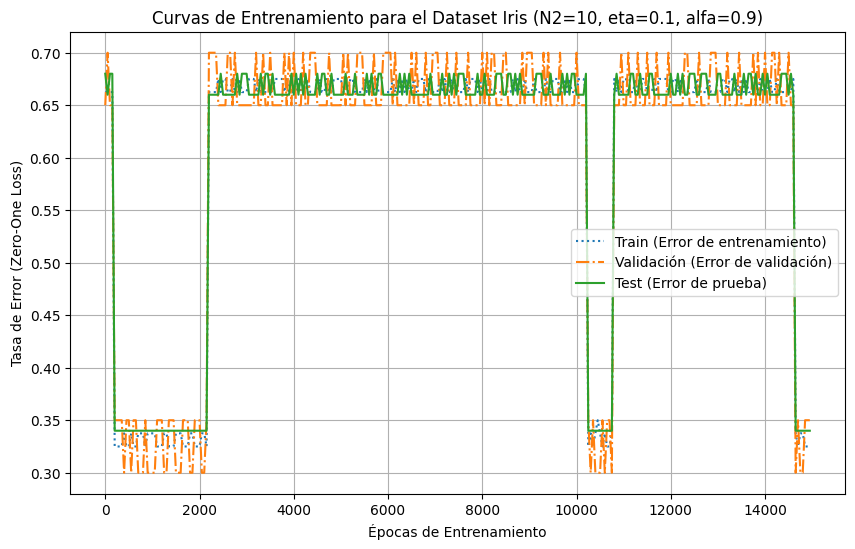

Mejor época según validación: Época 400
Error final de Clasificación en Test (Zero-One Loss): 0.3400 (34.00% de error)
Precisión final de clasificación en Test: 66.00%


In [52]:
N2 = 10              
sub_epocas = 50      
evaluaciones = 300   
eta = 0.1           
alfa = 0.9          

red_iris = MLPClassifier(
    hidden_layer_sizes=(N2,), 
    activation='logistic', 
    solver='sgd', 
    alpha=0.0,
    batch_size=1, 
    learning_rate='constant', 
    learning_rate_init=eta,
    momentum=alfa, 
    nesterovs_momentum=False, 
    tol=0.0, 
    warm_start=True,
    max_iter=sub_epocas
)

best_red, e_train, e_val, e_test = entrenar_red(
    red_iris, evaluaciones, 
    X_train, y_train, 
    X_val, y_val, 
    X_test, y_test, 
)

rango_epocas = np.array(range(evaluaciones)) * sub_epocas
plt.figure(figsize=(10, 6))
plt.plot(rango_epocas, e_train, label="Train (Error de entrenamiento)", linestyle=":")
plt.plot(rango_epocas, e_val,   label="Validación (Error de validación)", linestyle="-.")
plt.plot(rango_epocas, e_test,  label="Test (Error de prueba)", linestyle="-")
plt.xlabel("Épocas de Entrenamiento")
plt.ylabel("Tasa de Error (Zero-One Loss)")
plt.title(f"Curvas de Entrenamiento para el Dataset Iris (N2={N2}, eta={eta}, alfa={alfa})")
plt.grid(True)
plt.legend()
plt.show()
# Mostrar resultados del mejor modelo encontrado en el mínimo de validación
error_final_test = zero_one_loss(y_test, best_red.predict(X_test))
print(f"Mejor época según validación: Época {np.argmin(e_val) * sub_epocas}")
print(f"Error final de Clasificación en Test (Zero-One Loss): {error_final_test:.4f} ({error_final_test*100:.2f}% de error)")
print(f"Precisión final de clasificación en Test: {(1 - error_final_test)*100:.2f}%")

Tamaño de entrada (píxeles): 960 (Imagen de 30x32)
Patrones de entrenamiento: 208 muestras
Patrones de validación:    52 muestras
Patrones de test:          364 muestras


C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (10) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppD

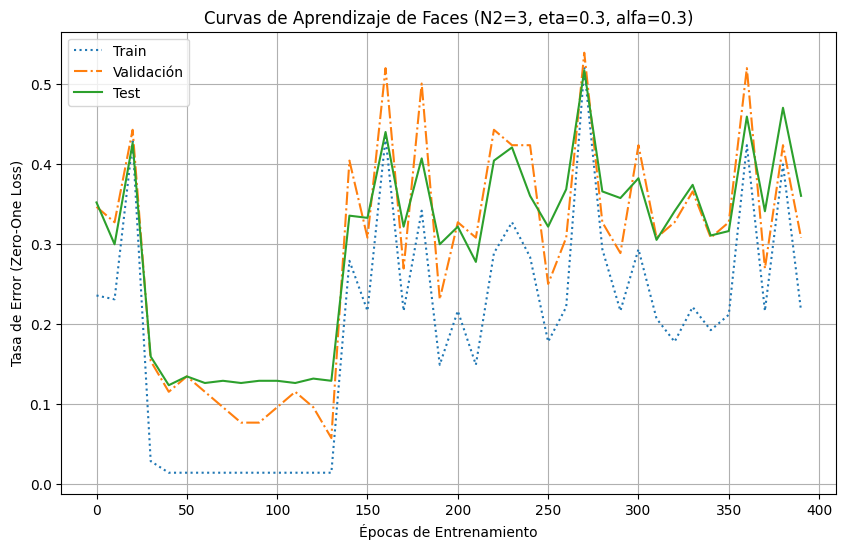


================ COMPARACIÓN CON MITCHELL ================
Exactitud obtenida en tu Test: 87.09%
Exactitud citada por Mitchell: ~90.00%
Diferencia: -2.91%


In [57]:
# 1. Cargar datos de Faces (960 columnas de píxeles + 1 columna de clase)
X_train_raw, y_train = cargar_csv('faces.data', xcols=960)
X_test_raw, y_test = cargar_csv('faces.test', xcols=960)

# 2. Re-escalar los datos de píxeles al rango [0, 1] dividiendo por 255.0
X_train = X_train_raw / 255.0
X_test = X_test_raw / 255.0

# Dado que no tenemos un archivo de validación separado, dividimos el Train en 80-20 para validación
X_tr, X_val, y_train_split, y_val = skl.model_selection.train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

print(f"Tamaño de entrada (píxeles): {X_tr.shape[1]} (Imagen de 30x32)")
print(f"Patrones de entrenamiento: {X_tr.shape[0]} muestras")
print(f"Patrones de validación:    {X_val.shape[0]} muestras")
print(f"Patrones de test:          {X_test.shape[0]} muestras")

# 3. Parámetros basados en el experimento de Mitchell (pág. 112)
N2 = 3               # Mitchell utiliza exactamente 3 unidades en la capa oculta
eta = 0.3            # Tasa de aprendizaje de Mitchell
alfa = 0.3           # Momentum de Mitchell
sub_epocas = 10      # Evaluamos el error cada 10 épocas
evaluaciones = 40    # 40 evaluaciones x 10 = 400 épocas en total para asegurar convergencia

# Definir la red
red_faces = MLPClassifier(
    hidden_layer_sizes=(N2,), 
    activation='logistic', 
    solver='sgd', 
    alpha=0.0,
    batch_size=1, 
    learning_rate='constant', 
    learning_rate_init=eta,
    momentum=alfa, 
    nesterovs_momentum=False, 
    tol=0.0, 
    warm_start=True,
    max_iter=sub_epocas,
    random_state=None
)

# 4. Entrenar la red neuronal
mejor_red, e_train, e_val, e_test = entrenar_red(
    red_faces, evaluaciones, 
    X_tr, y_train_split, 
    X_val, y_val, 
    X_test, y_test, 
    regressor=False
)

# 5. Mostrar gráficas de entrenamiento para asegurar la convergencia
rango_epocas = np.array(range(evaluaciones)) * sub_epocas

plt.figure(figsize=(10, 6))
plt.plot(rango_epocas, e_train, label="Train", linestyle=":")
plt.plot(rango_epocas, e_val,   label="Validación", linestyle="-.")
plt.plot(rango_epocas, e_test,  label="Test", linestyle="-")
plt.xlabel("Épocas de Entrenamiento")
plt.ylabel("Tasa de Error (Zero-One Loss)")
plt.title(f"Curvas de Aprendizaje de Faces (N2={N2}, eta={eta}, alfa={alfa})")
plt.grid(True)
plt.legend()
plt.show()

# 6. Comparación con los resultados de Mitchell
error_final_test = zero_one_loss(y_test, mejor_red.predict(X_test))
exactitud_final = (1 - error_final_test) * 100

print("\n================ COMPARACIÓN CON MITCHELL ================")
print(f"Exactitud obtenida en tu Test: {exactitud_final:.2f}%")
print(f"Exactitud citada por Mitchell: ~90.00%")
print(f"Diferencia: {exactitud_final - 90.0:.2f}%")
print("==========================================================")

Entradas ($X$): Las primeras 960 columnas representan los valores de los píxeles de una imagen de $30 \times 32$ píxeles en escala de grises. Los valores originales van de $0$ a $255$ (por eso el enunciado te pide explícitamente re-escalarlos al rango $[0, 1]$ dividiéndolos por $255.0$ antes de entrenar).
Salida ($y$): La última columna representa la variable objetivo (la orientación de la cara). Es una clasificación multiclase.

# (OPCIONAL) Ejercicio 7. Minibatch.

Tamaño de entrenamiento: 144 muestras
Tamaño de validación:    36 muestras
Tamaño de test:          107 muestras

Entrenando red con batch_size = 1...
Finalizado batch_size=1. MSE final en Test: 0.004544

Entrenando red con batch_size = 5...


C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Finalizado batch_size=5. MSE final en Test: 0.005510

Entrenando red con batch_size = 10...


C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


Finalizado batch_size=10. MSE final en Test: 0.005378

Entrenando red con batch_size = 25...


C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\A

Finalizado batch_size=25. MSE final en Test: 0.005353

Entrenando red con batch_size = 40...


C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\ignac\A

Finalizado batch_size=40. MSE final en Test: 0.005545



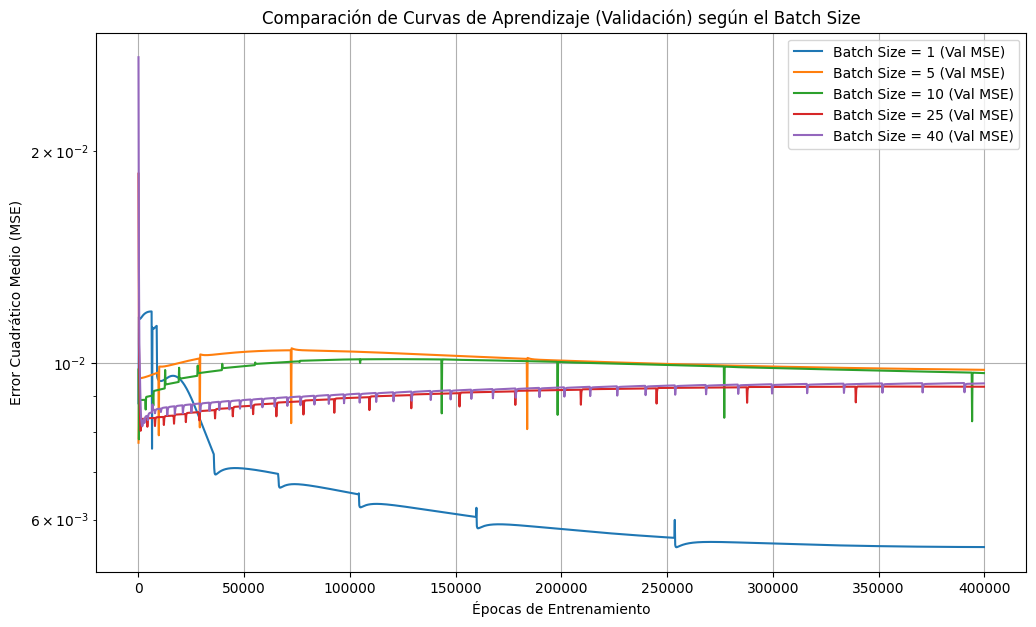

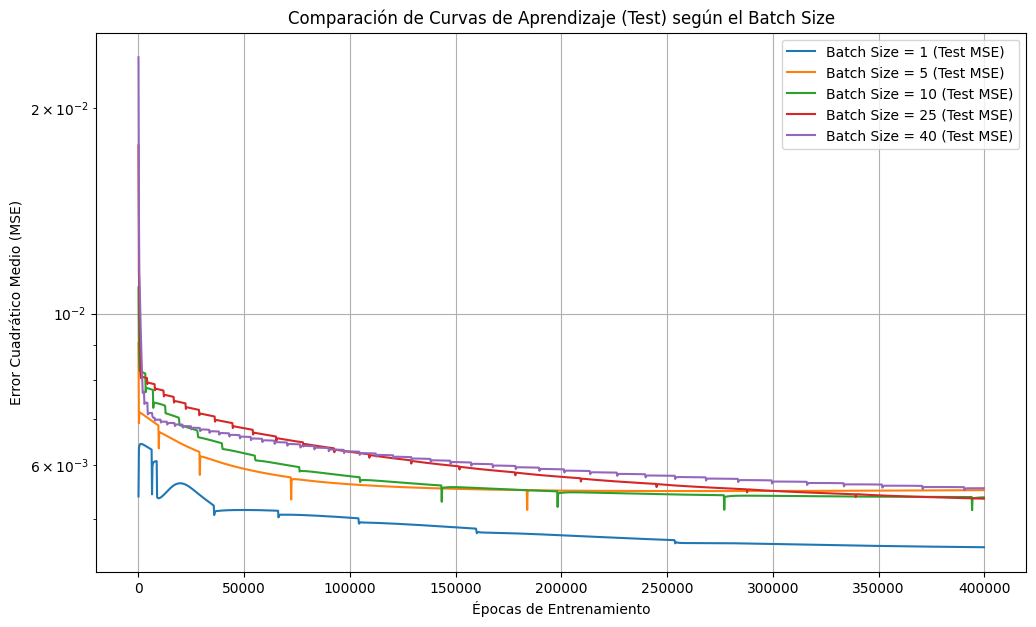

In [59]:

# 1. Cargar datos de Sunspots (ssp)
# ssp tiene 12 columnas de entrada y la 13° es la de salida (actividad solar)
X_ajuste, y_ajuste = cargar_csv('ssp.data', xcols=12)
X_test, y_test = cargar_csv('ssp.test', xcols=12)
# 2. Partición: 20% para validación, 80% para entrenamiento
X_train, X_val, y_train, y_val = skl.model_selection.train_test_split(
    X_ajuste, y_ajuste, test_size=0.2, random_state=42
)
print(f"Tamaño de entrenamiento: {X_train.shape[0]} muestras")
print(f"Tamaño de validación:    {X_val.shape[0]} muestras")
print(f"Tamaño de test:          {X_test.shape[0]} muestras\n")
# Parámetros del enunciado
N2 = 6                 # Neuronas ocultas
eta = 0.05             # Learning rate
alfa = 0.3            # Momentum
evaluaciones = 2000    # Evaluaciones de entrenamiento
sub_epocas = 200       # Épocas por evaluación (2000 x 200 = 400.000 épocas en total)
# Definimos los tres tamaños de batch que compararemos
batch_sizes = [1, 5, 10, 25, 40]
curvas_por_batch = {}
for bs in batch_sizes:
    print(f"Entrenando red con batch_size = {bs}...")
    
    # Definición de la red
    regr = MLPRegressor(
        hidden_layer_sizes=(N2,), 
        activation='logistic', 
        solver='sgd', 
        alpha=0.0,
        batch_size=bs,              # <--- Variamos el tamaño de lote
        learning_rate='constant', 
        learning_rate_init=eta,
        momentum=alfa, 
        nesterovs_momentum=False, 
        tol=0.0, 
        warm_start=True,
        max_iter=sub_epocas,
        random_state=42
    )
    
    # Entrenar utilizando tu función entrenar_red (regressor=True)
    best_red, e_train, e_val, e_test = entrenar_red(
        regr, evaluaciones, 
        X_train, y_train, 
        X_val, y_val, 
        X_test, y_test, 
        regressor=True
    )
    
    # Guardar las curvas para comparar
    curvas_por_batch[bs] = (e_train, e_val, e_test)
    print(f"Finalizado batch_size={bs}. MSE final en Test: {e_test[-1]:.6f}\n")
# 3. Graficar comparando el MSE de Validación para los tres batch_sizes
rango_epocas = np.array(range(evaluaciones)) * sub_epocas
plt.figure(figsize=(12, 7))
for bs in batch_sizes:
    e_train, e_val, e_test = curvas_por_batch[bs]
    plt.plot(rango_epocas, e_val, label=f"Batch Size = {bs} (Val MSE)")
plt.xlabel("Épocas de Entrenamiento")
plt.ylabel("Error Cuadrático Medio (MSE)")
plt.title("Comparación de Curvas de Aprendizaje (Validación) según el Batch Size")
plt.grid(True)
plt.yscale("log")  # Usamos escala logarítmica en Y para apreciar mejor la convergencia fina
plt.legend()
plt.show()
# 4. Graficar comparando el MSE de Test para los tres batch_sizes
plt.figure(figsize=(12, 7))
for bs in batch_sizes:
    e_train, e_val, e_test = curvas_por_batch[bs]
    plt.plot(rango_epocas, e_test, label=f"Batch Size = {bs} (Test MSE)")
plt.xlabel("Épocas de Entrenamiento")
plt.ylabel("Error Cuadrático Medio (MSE)")
plt.title("Comparación de Curvas de Aprendizaje (Test) según el Batch Size")
plt.grid(True)
plt.yscale("log")
plt.legend()
plt.show()